In [3]:
import pandas as pd

df = pd.read_csv("../data/ecommerce_sales_customer_analytics.csv")

df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,City,Category,Product,Quantity,Unit_Price,Discount_Percent,Sales,Profit,Payment_Method,Order_Status
0,ORD10001,2025-06-10,CUST1052,Nandhini G.,Delhi,Home & Kitchen,Storage Container Set,1,799,10.0,719.10,97.08,UPI,Delivered
1,ORD10002,2025-04-29,CUST1102,Divya W.,Hyderabad,Electronics,Bluetooth Speaker,3,1999,5.0,5697.15,1125.19,Credit Card,Delivered
2,ORD10003,2025-05-29,CUST1141,Swathi B.,Jaipur,Electronics,Smart Watch,1,2499,20.0,1999.20,319.87,Credit Card,Delivered
3,ORD10004,2025-05-30,CUST1038,Pooja W.,Mumbai,Fashion,Sports Shoes,2,2199,20.0,3518.40,738.86,Credit Card,Delivered
4,ORD10005,2025-10-20,CUST1162,Suresh E.,Hyderabad,Fashion,Women's Kurti,5,999,0.0,4995.00,1598.40,UPI,Delivered


In [3]:
print("Rows and Columns:", df.shape)

Rows and Columns: (1005, 14)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          1005 non-null   str    
 1   Order_Date        1005 non-null   str    
 2   Customer_ID       1005 non-null   str    
 3   Customer_Name     1005 non-null   str    
 4   City              1004 non-null   str    
 5   Category          1004 non-null   str    
 6   Product           1004 non-null   str    
 7   Quantity          1005 non-null   int64  
 8   Unit_Price        1005 non-null   int64  
 9   Discount_Percent  1004 non-null   float64
 10  Sales             1005 non-null   float64
 11  Profit            1005 non-null   float64
 12  Payment_Method    1004 non-null   str    
 13  Order_Status      1005 non-null   str    
dtypes: float64(3), int64(2), str(9)
memory usage: 110.1 KB


In [6]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
City                1
Category            1
Product             1
Quantity            0
Unit_Price          0
Discount_Percent    1
Sales               0
Profit              0
Payment_Method      1
Order_Status        0
dtype: int64

In [8]:
print("Duplicates before cleaning:", df.duplicated().sum())

Duplicates before cleaning: 5


In [10]:
df = df.drop_duplicates()
print("Duplicates after cleaning:", df.duplicated().sum())
print("New shape:", df.shape)

Duplicates after cleaning: 0
New shape: (1000, 14)


In [12]:
#handling missing values
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
City                1
Category            1
Product             1
Quantity            0
Unit_Price          0
Discount_Percent    1
Sales               0
Profit              0
Payment_Method      1
Order_Status        0
dtype: int64

In [14]:
df["City"] = df["City"].fillna(df["City"].mode()[0])

df["Category"] = df["Category"].fillna(df["Category"].mode()[0])

df["Product"] = df["Product"].fillna(df["Product"].mode()[0])

df["Payment_Method"] = df["Payment_Method"].fillna(
    df["Payment_Method"].mode()[0]
)

In [17]:
df["Discount_Percent"] = df["Discount_Percent"].fillna(
    df["Discount_Percent"].median()
)

In [19]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Name       0
City                0
Category            0
Product             0
Quantity            0
Unit_Price          0
Discount_Percent    0
Sales               0
Profit              0
Payment_Method      0
Order_Status        0
dtype: int64

In [22]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [24]:
df.dtypes

Order_ID                str
Order_Date              str
Customer_ID             str
Customer_Name           str
City                    str
Category                str
Product                 str
Quantity              int64
Unit_Price            int64
Discount_Percent    float64
Sales               float64
Profit              float64
Payment_Method          str
Order_Status            str
dtype: object

In [26]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [27]:
print(df["Order_Date"].dtype)

datetime64[us]


In [28]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Rows: 1000
Columns: 14
Missing values: 0
Duplicates: 0


In [41]:
#EDA-Exploratory data analysis
# KPI Analysis

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")


Total Sales: 2122485.75
Total Profit: 417617.47
Total Orders: 1000
Total Customers: 223
Total Quantity Sold: 1764
Average Order Value: 2122.49
Profit Margin: 19.68 %


In [ ]:
#monthly sales
#Create Month columns
df["Month"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%B")

In [31]:
#calculate monthly sales
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = (
    df.groupby("Month_Name")["Sales"]
    .sum()
    .reindex(month_order)
)

print(monthly_sales)

Month_Name
January      159793.95
February     168384.55
March        201478.85
April        201407.75
May          223374.85
June         165391.95
July         128816.40
August       182673.45
September    184800.40
October      211918.85
November     150321.65
December     135884.65
Name: Sales, dtype: float64


In [32]:
#highest and lowest sales months
best_month = monthly_sales.idxmax()
best_sales = monthly_sales.max()

worst_month = monthly_sales.idxmin()
worst_sales = monthly_sales.min()

print("Highest Sales Month:", best_month)
print("Highest Sales:", round(best_sales, 2))

print("Lowest Sales Month:", worst_month)
print("Lowest Sales:", round(worst_sales, 2))

Highest Sales Month: May
Highest Sales: 223374.85
Lowest Sales Month: July
Lowest Sales: 128816.4


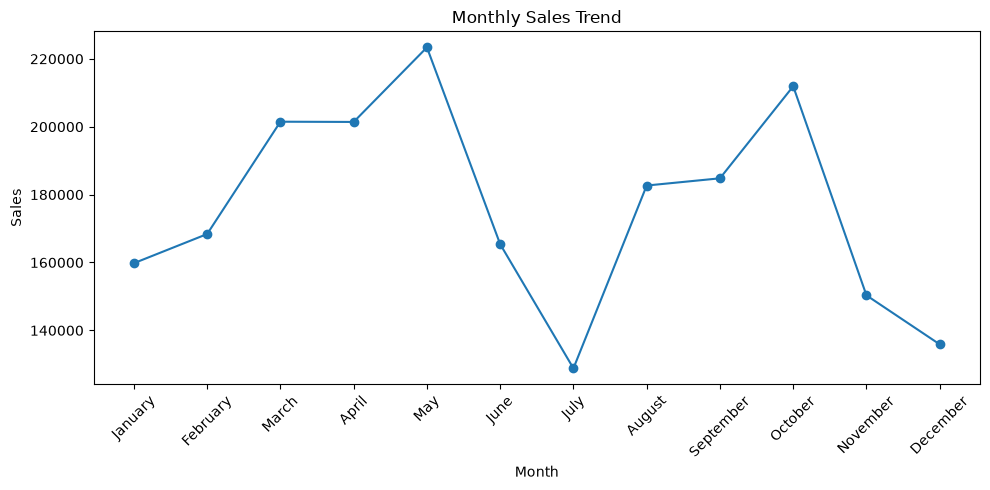

In [35]:
# sales trend chart
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:
# Calculate sales by category

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)


Category
Electronics       812177.05
Home & Kitchen    613885.50
Fashion           460278.60
Beauty            140625.35
Books              87280.80
Name: Sales, dtype: float64


In [37]:
# Calculate profit by category
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(category_profit)


Category
Electronics       162917.15
Fashion           122894.51
Home & Kitchen     84413.88
Beauty             31612.98
Books              13957.36
Name: Profit, dtype: float64


In [40]:
import matplotlib.pyplot as plt

category_analysis = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

print(category_analysis)


                    Sales     Profit
Category                            
Electronics     812177.05  162917.15
Home & Kitchen  613885.50   84413.88
Fashion         460278.60  122894.51
Beauty          140625.35   31612.98
Books            87280.80   13957.36


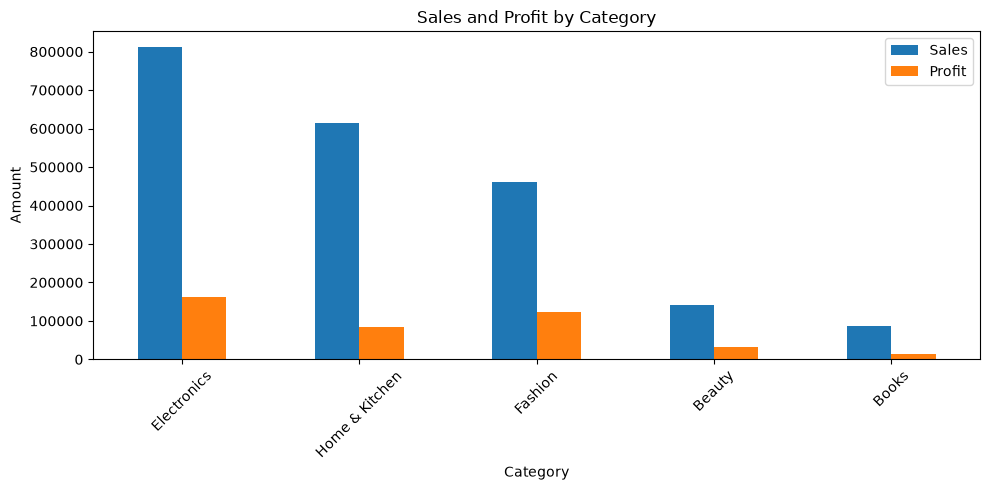

In [41]:
import matplotlib.pyplot as plt

category_analysis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Sales and Profit by Category")
plt.xlabel("Category")
plt.ylabel("Amount")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [42]:
#Top 10 products by sales
top_products_sales = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)



print(top_products_sales)


Product
Smart Watch            286135.50
Bluetooth Speaker      248430.20
Mixer Grinder          223177.35
Cookware Set           211915.20
Wireless Headphones    163690.80
Sports Shoes           154809.60
Jeans                  140152.35
Electric Kettle        112883.10
Power Bank             111116.40
Women's Kurti          100449.45
Name: Sales, dtype: float64


In [44]:
# Top 10 products by profit
top_products_profit = (
    df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products_profit)

Product
Smart Watch            60440.26
Bluetooth Speaker      45229.19
Sports Shoes           40055.29
Wireless Headphones    39644.50
Jeans                  34639.40
Mixer Grinder          30919.49
Women's Kurti          28476.58
Cookware Set           26137.66
Men's T-Shirt          19723.24
Electric Kettle        18066.79
Name: Profit, dtype: float64


In [1]:
# Visualize top products by sales
top_products_sales.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

NameError: name 'top_products_sales' is not defined

In [5]:
# Top Customers by Sales

customer_sales = (
    df.groupby(["Customer_ID", "Customer_Name"])["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(customer_sales.head(10))

Customer_ID  Customer_Name
CUST1000     Vijay T.         124589.65
CUST1001     Hari K.           83130.50
CUST1002     Meena U.          67670.60
CUST1003     Vijay Z.          56192.70
CUST1004     Vikram W.         51698.95
CUST1007     Rahul V.          34629.70
CUST1042     Ajay I.           31835.45
CUST1008     Priya X.          30795.35
CUST1068     Vikram G.         29431.45
CUST1010     Priya U.          26991.30
Name: Sales, dtype: float64


In [7]:
#Top customers by profit
customer_profit = (
    df.groupby(["Customer_ID", "Customer_Name"])["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(customer_profit.head(10))
    

Customer_ID  Customer_Name
CUST1000     Vijay T.         22727.40
CUST1001     Hari K.          16993.60
CUST1002     Meena U.         13705.67
CUST1003     Vijay Z.         12046.52
CUST1004     Vikram W.         9314.68
CUST1068     Vikram G.         6902.95
CUST1008     Priya X.          6469.89
CUST1007     Rahul V.          6437.38
CUST1018     Rahul E.          6142.67
CUST1010     Priya U.          5434.95
Name: Profit, dtype: float64


In [8]:
# Find repeat customers
orders_per_customer = df.groupby("Customer_ID")["Order_ID"].nunique()

repeat_customers = orders_per_customer[orders_per_customer > 1]

print("Total Customers:", df["Customer_ID"].nunique())
print("Repeat Customers:", len(repeat_customers))

Total Customers: 223
Repeat Customers: 184


In [10]:
# Calculate repeat customer percentage
repeat_percentage = (
    len(repeat_customers) / df["Customer_ID"].nunique()
) * 100

print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")


Repeat Customer Percentage: 82.51 %


In [13]:
#City-wise Sales Analysis
city_sales = (
    df.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(city_sales)


City
Jaipur        379999.10
Delhi         292749.20
Ahmedabad     277365.15
Hyderabad     243172.00
Bengaluru     202385.80
Chennai       193752.05
Kolkata       165959.90
Mumbai        156642.65
Coimbatore    112682.20
Pune           92779.70
Name: Sales, dtype: float64


In [15]:
#Top 10 cities
top_cities = city_sales.head(10)

print(top_cities)

City
Jaipur        379999.10
Delhi         292749.20
Ahmedabad     277365.15
Hyderabad     243172.00
Bengaluru     202385.80
Chennai       193752.05
Kolkata       165959.90
Mumbai        156642.65
Coimbatore    112682.20
Pune           92779.70
Name: Sales, dtype: float64


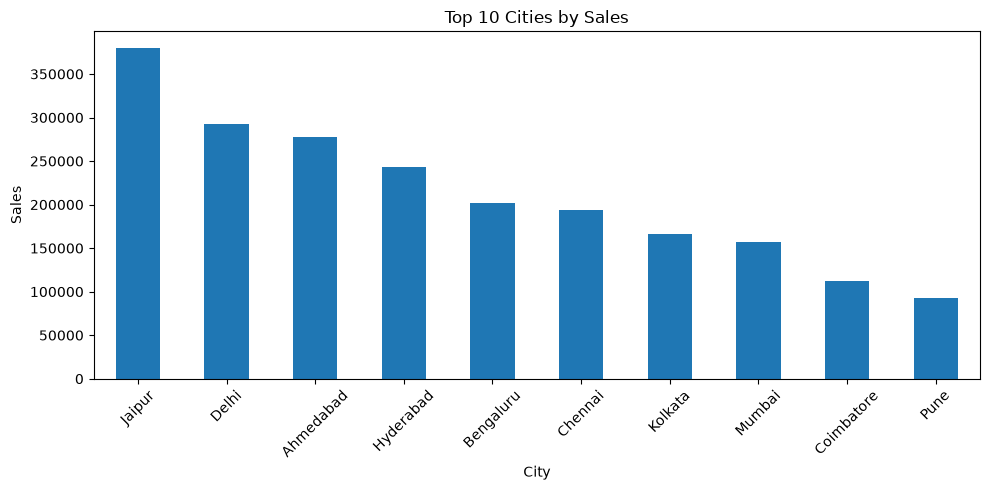

In [17]:
import matplotlib.pyplot as plt
top_cities.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Cities by Sales")
plt.xlabel("City")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [18]:
#Payment Method Analysis
payment_counts = df["Payment_Method"].value_counts()

print(payment_counts)

Payment_Method
UPI                 358
Credit Card         263
Debit Card          181
Cash on Delivery    139
Net Banking          63
Name: count, dtype: int64


In [19]:
# Calculate sales by payment method
payment_sales = (
    df.groupby("Payment_Method")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_sales)

Payment_Method
UPI                 719172.65
Credit Card         602856.35
Debit Card          363595.15
Cash on Delivery    306942.25
Net Banking         127924.35
Name: Sales, dtype: float64


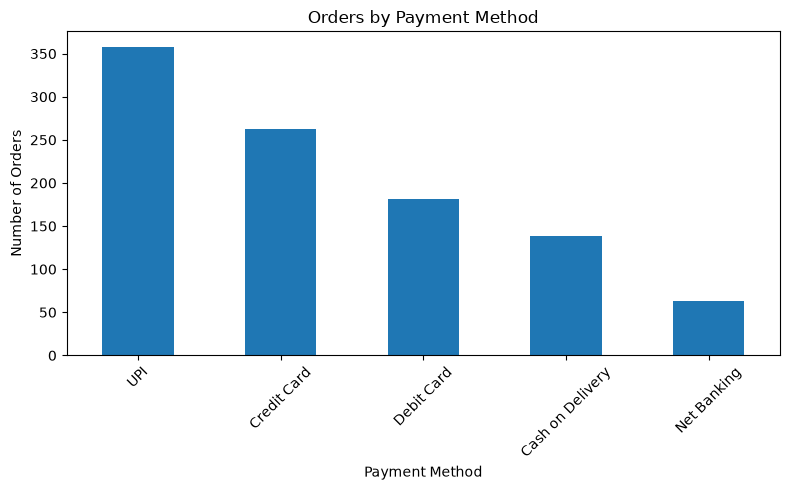

In [20]:
import matplotlib.pyplot as plt
payment_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
# Order Status Analysis
order_status_counts = df["Order_Status"].value_counts()

print(order_status_counts)

Order_Status
Delivered    862
Shipped       61
Cancelled     57
Returned      25
Name: count, dtype: int64


In [22]:
# Calculate sales by order status
status_sales = (
    df.groupby("Order_Status")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(status_sales)

Order_Status
Delivered    1916613.55
Shipped       142554.60
Returned       63317.60
Cancelled          0.00
Name: Sales, dtype: float64


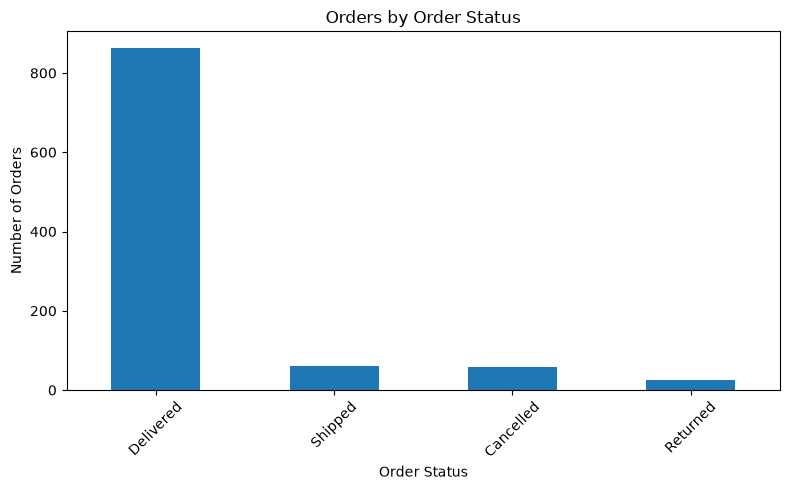

In [23]:
import matplotlib.pyplot as plt
order_status_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Orders by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [24]:
# Profitability Analysis
category_profitability = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

category_profitability["Profit_Margin_%"] = (
    category_profitability["Profit"]
    / category_profitability["Sales"]
) * 100

category_profitability = category_profitability.sort_values(
    "Profit_Margin_%",
    ascending=False
)

print(category_profitability)


                    Sales     Profit  Profit_Margin_%
Category                                             
Fashion         464174.70  124100.80        26.735796
Beauty          141194.40   31759.51        22.493463
Electronics     811271.95  162976.74        20.089039
Books            87280.80   13957.36        15.991329
Home & Kitchen  615759.75   84507.59        13.724117


In [ ]:
category_profitability = category_profitability.round(2)

print(category_profitability)

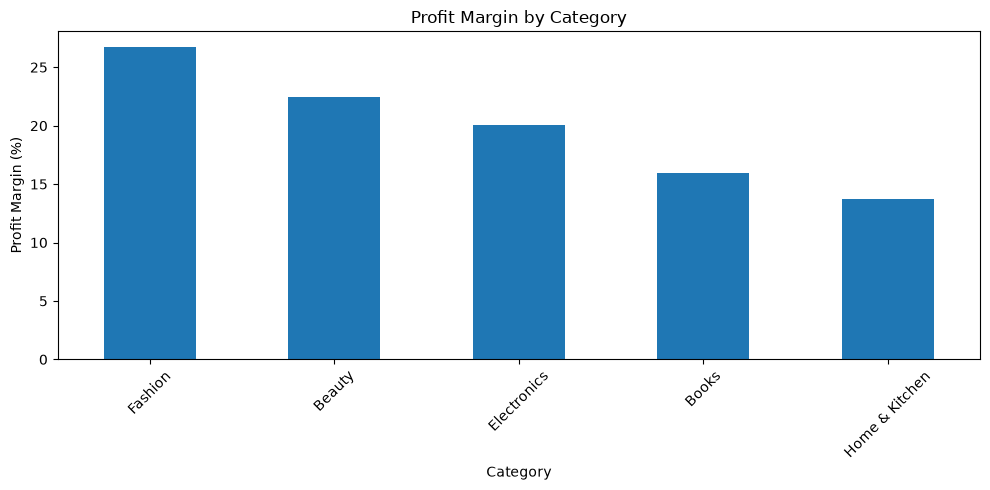

In [ ]:
import matplotlib.pyplot as plt
category_profitability["Profit_Margin_%"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [26]:
# Discount Analysis
discount_analysis = (
    df.groupby("Discount_Percent")
    .agg(
        Orders=("Order_ID", "nunique"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_index()
)

print(discount_analysis)


                  Orders      Sales     Profit
Discount_Percent                              
0.0                  205  513296.00  118960.27
5.0                  193  437497.80   96709.02
10.0                 281  570774.60  108891.00
15.0                 175  353646.75   59431.70
20.0                  88  161123.20   23240.06
25.0                  57   84725.25   10033.44


In [27]:
# Calculate profit margin
discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Profit"] /
    discount_analysis["Sales"]
) * 100

discount_analysis = discount_analysis.round(2)

print(discount_analysis)


                  Orders      Sales     Profit  Profit_Margin_%
Discount_Percent                                               
0.0                  205  513296.00  118960.27            23.18
5.0                  193  437497.80   96709.02            22.11
10.0                 281  570774.60  108891.00            19.08
15.0                 175  353646.75   59431.70            16.81
20.0                  88  161123.20   23240.06            14.42
25.0                  57   84725.25   10033.44            11.84


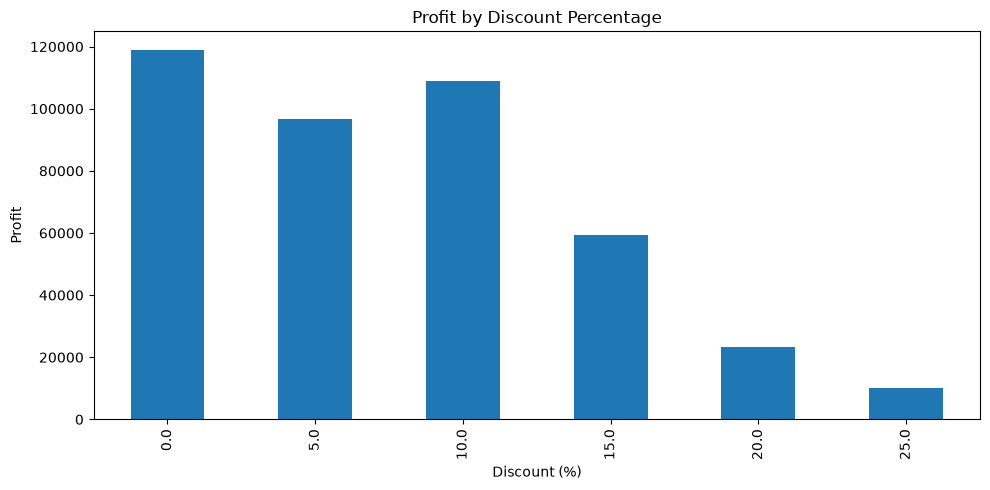

In [28]:

import matplotlib.pyplot as plt
discount_analysis["Profit"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Profit by Discount Percentage")
plt.xlabel("Discount (%)")
plt.ylabel("Profit")

plt.tight_layout()
plt.show()

In [30]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [31]:
# Customer Segmentation (RFM Analysis)
reference_date = df["Order_Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer_ID").agg(
    Recency=("Order_Date", lambda x: (reference_date - x.max()).days),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Sales", "sum")
)

print(rfm.head(10))

             Recency  Frequency   Monetary
Customer_ID                               
CUST1000           2         55  124589.65
CUST1001          12         38   83130.50
CUST1002          12         28   67670.60
CUST1003          23         20   56192.70
CUST1004          11         21   51698.95
CUST1005          23         14   25679.15
CUST1006           4         15   21042.90
CUST1007           5         13   34629.70
CUST1008          37         11   30795.35
CUST1009          10         15   26418.50


In [33]:
#RFM summary
print(rfm.describe())

          Recency   Frequency       Monetary
count  223.000000  223.000000     223.000000
mean    97.345291    4.484305    9517.873318
std     87.362721    5.414235   12939.527356
min      1.000000    1.000000       0.000000
25%     28.500000    2.000000    2737.250000
50%     75.000000    3.000000    6395.500000
75%    137.000000    5.000000   10870.525000
max    352.000000   55.000000  124589.650000


In [34]:
# Creating customer segments
def customer_segment(row):
    if row["Frequency"] >= 5 and row["Monetary"] >= 10000:
        return "High Value"
    elif row["Frequency"] >= 3:
        return "Loyal"
    elif row["Recency"] <= 60:
        return "Recent"
    else:
        return "At Risk"

rfm["Segment"] = rfm.apply(customer_segment, axis=1)

print(rfm.head(10))


             Recency  Frequency   Monetary     Segment
Customer_ID                                           
CUST1000           2         55  124589.65  High Value
CUST1001          12         38   83130.50  High Value
CUST1002          12         28   67670.60  High Value
CUST1003          23         20   56192.70  High Value
CUST1004          11         21   51698.95  High Value
CUST1005          23         14   25679.15  High Value
CUST1006           4         15   21042.90  High Value
CUST1007           5         13   34629.70  High Value
CUST1008          37         11   30795.35  High Value
CUST1009          10         15   26418.50  High Value


In [36]:
# Count customers in each segment
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
Loyal         87
At Risk       64
High Value    54
Recent        18
Name: count, dtype: int64


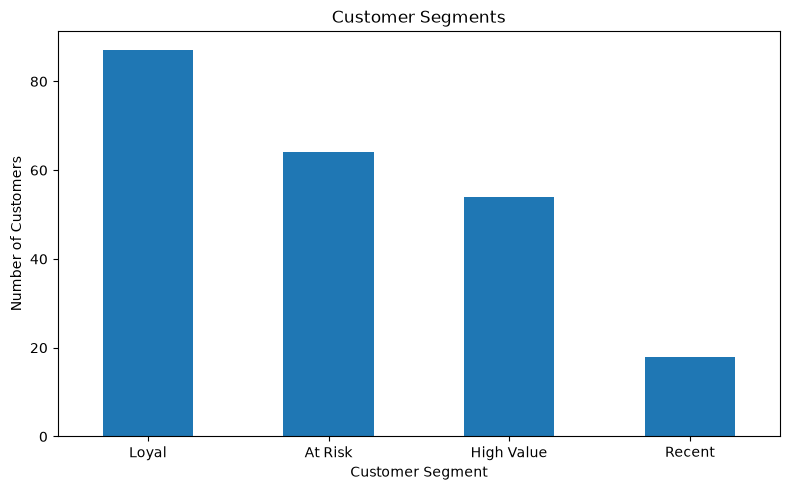

In [37]:
import matplotlib.pyplot as plt
segment_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [38]:
#  correlation matrix
correlation = df[
    ["Quantity", "Unit_Price", "Discount_Percent", "Sales", "Profit"]
].corr()

print(correlation.round(2))

                  Quantity  Unit_Price  Discount_Percent  Sales  Profit
Quantity              1.00       -0.03             -0.02   0.61    0.60
Unit_Price           -0.03        1.00              0.01   0.59    0.46
Discount_Percent     -0.02        0.01              1.00  -0.13   -0.28
Sales                 0.61        0.59             -0.13   1.00    0.91
Profit                0.60        0.46             -0.28   0.91    1.00


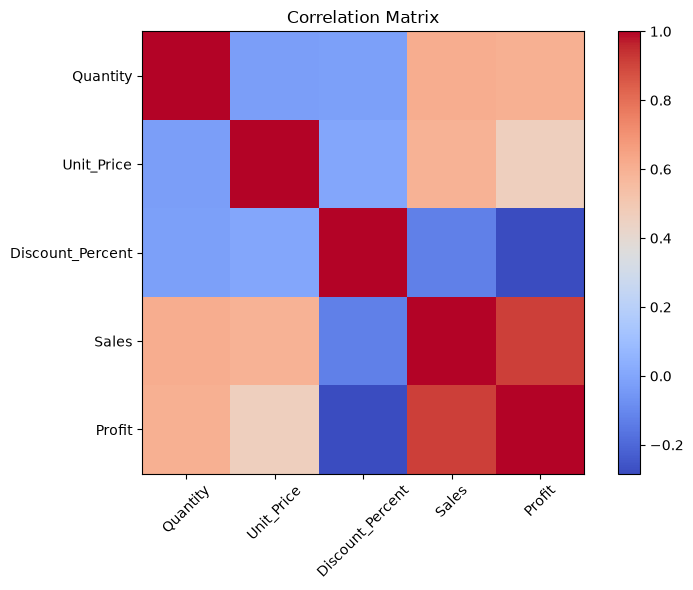

In [39]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [44]:
# ==========================================
# FINAL BUSINESS INSIGHTS
# ==========================================

print("===== KEY BUSINESS INSIGHTS =====")

# 1. Overall Performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
total_quantity = df["Quantity"].sum()

average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("\n1. Overall Performance")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Quantity Sold:", total_quantity)
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")


# 2. Monthly Performance
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

monthly_sales = (
    df.groupby(df["Order_Date"].dt.month)["Sales"]
    .sum()
)

best_month_number = monthly_sales.idxmax()
best_sales = monthly_sales.max()

worst_month_number = monthly_sales.idxmin()
worst_sales = monthly_sales.min()

best_month = pd.to_datetime(
    str(best_month_number), format="%m"
).strftime("%B")

worst_month = pd.to_datetime(
    str(worst_month_number), format="%m"
).strftime("%B")

print("\n2. Monthly Performance")
print("Highest Sales Month:", best_month)
print("Highest Monthly Sales:", round(best_sales, 2))
print("Lowest Sales Month:", worst_month)
print("Lowest Monthly Sales:", round(worst_sales, 2))


# 3. Category Performance
category_analysis = (
    df.groupby("Category")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

print("\n3. Category Performance")
print(category_analysis.round(2))


# 4. Top 10 Products
top_products_sales = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\n4. Top 10 Products by Sales")
print(top_products_sales.round(2))


# 5. Customer Performance
orders_per_customer = (
    df.groupby("Customer_ID")["Order_ID"]
    .nunique()
)

repeat_customers = orders_per_customer[
    orders_per_customer > 1
]

repeat_percentage = (
    len(repeat_customers) / total_customers
) * 100

print("\n5. Customer Performance")
print("Total Customers:", total_customers)
print("Repeat Customers:", len(repeat_customers))
print(
    "Repeat Customer Percentage:",
    round(repeat_percentage, 2),
    "%"
)


# 6. Top Cities
city_sales = (
    df.groupby("City")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

top_cities = city_sales.head(10)

print("\n6. Top Cities")
print(top_cities.round(2))


# 7. Customer Segments
# Recreate RFM if needed

reference_date = df["Order_Date"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer_ID").agg(
    Recency=(
        "Order_Date",
        lambda x: (reference_date - x.max()).days
    ),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Sales", "sum")
)

def customer_segment(row):
    if row["Frequency"] >= 5 and row["Monetary"] >= 10000:
        return "High Value"
    elif row["Frequency"] >= 3:
        return "Loyal"
    elif row["Recency"] <= 60:
        return "Recent"
    else:
        return "At Risk"

rfm["Segment"] = rfm.apply(customer_segment, axis=1)

segment_counts = rfm["Segment"].value_counts()

print("\n7. Customer Segments")
print(segment_counts)

===== KEY BUSINESS INSIGHTS =====

1. Overall Performance
Total Sales: 2122485.75
Total Profit: 417617.47
Total Orders: 1000
Total Customers: 223
Total Quantity Sold: 1764
Average Order Value: 2122.49
Profit Margin: 19.68 %

2. Monthly Performance
Highest Sales Month: May
Highest Monthly Sales: 223374.85
Lowest Sales Month: July
Lowest Monthly Sales: 131813.4

3. Category Performance
                    Sales     Profit
Category                            
Electronics     811271.95  162976.74
Home & Kitchen  615759.75   84507.59
Fashion         464174.70  124100.80
Beauty          141194.40   31759.51
Books            87280.80   13957.36

4. Top 10 Products by Sales
Product
Smart Watch            286135.50
Bluetooth Speaker      249475.20
Mixer Grinder          223177.35
Cookware Set           213789.45
Wireless Headphones    163690.80
Sports Shoes           154809.60
Jeans                  140152.35
Electric Kettle        112883.10
Power Bank             111116.40
Women's Kurti       

In [45]:
df.to_csv("../data/ecommerce_sales_customer_analytics_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [49]:
# final validation
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

Rows: 1000
Columns: 14
Missing values: 0
Duplicates: 0


In [50]:
df.to_csv(
    "../data/ecommerce_sales_customer_analytics_cleaned.csv",
    index=False
)

print("Cleaned dataset saved!")

Cleaned dataset saved!
